# SIS 1: Exchange rates and national economies

Team: Dauletkhan Qian (23B031082), Kalybay Nurdaulet (23B031515), Dauirkhankyzy Balnur (23B031274), Abibulla Kundyz (23B030352)

Topic: is the size of an economy (GDP) connected with how its currency changes against the US dollar?

- API: World Bank (exchange rate, inflation, country info)
- Web scraping: Wikipedia "List of countries by GDP (nominal)"

Every member did one part in a separate notebook (01-04), and the parts pass data to each other through csv files in `data/`.
This notebook is all 4 parts together.

| Part | Who |
|---|---|
| 1. API | Dauletkhan Qian |
| 2. Web scraping | Kalybay Nurdaulet |
| 3. Cleaning and merging | Dauirkhankyzy Balnur |
| 4. Analysis and plots | Abibulla Kundyz |

# Part 1. Collecting data from the World Bank API
Author: **Dauletkhan Qian**

In this notebook we download two indicators from the World Bank API for 2015-2025:
- `PA.NUS.FCRF` - official exchange rate (local currency per 1 USD, average for the year)
- `FP.CPI.TOTL.ZG` - inflation (%)

We also download the list of countries, because it has region and income group.

Result: `data/wb_countries_raw.csv` and `data/wb_indicators_raw.csv`

## About the data

**Source:** World Bank, *World Development Indicators* (WDI). This is the main World Bank database with statistics
for about 217 countries. The API is free and does not need a key. Documentation:
https://datahelpdesk.worldbank.org/knowledgebase/articles/889392

**Indicators we use**

| Code | Name | Unit | How often | Original source |
|---|---|---|---|---|
| `PA.NUS.FCRF` | Official exchange rate | local currency units per 1 USD | yearly (average of the year) | IMF International Financial Statistics |
| `FP.CPI.TOTL.ZG` | Inflation, consumer prices | % change of prices compared to the previous year | yearly | IMF, national statistics |

**How to read the exchange rate:** the number shows how many units of the local currency you pay for 1 US dollar.
For example, Kazakhstan 2024 = about 470 means 1 USD is about 470 tenge on average in 2024.
If the number becomes bigger, the currency became **weaker**. Numbers of different countries cannot be compared directly
(1 USD is about 0.9 euro but about 15,000 Indonesian rupiah), only the **change** inside one country makes sense.

**How to read inflation:** 5 means that prices in the country grew by 5% during the year.

**Country list** (`/country`): for every country the API gives ISO3 code, name, region
(e.g. "Europe & Central Asia") and income group ("High income", "Upper middle income", "Lower middle income", "Low income").
The income group is decided by the World Bank from GNI per person.

**Period:** 2015-2025 (11 years). We chose 2015 because it is ten full years before the last available year,
and it includes several big events (2020 COVID, 2022 strong dollar).

**What one API record looks like:** one record = one country + one year + one indicator.

In [1]:
import os
import time
import requests
import pandas as pd

os.makedirs("data", exist_ok=True)

BASE_URL = "https://api.worldbank.org/v2"
HEADERS = {"User-Agent": "SIS1 student project"}

First we test one request to see what the API returns.

In [2]:
r = requests.get(BASE_URL + "/country/KAZ/indicator/PA.NUS.FCRF",
                 params={"format": "json", "date": "2024"}, headers=HEADERS)
print(r.status_code)
r.json()

200


[{'page': 1,
  'pages': 1,
  'per_page': 50,
  'total': 1,
  'sourceid': '2',
  'lastupdated': '2026-07-13'},
 [{'indicator': {'id': 'PA.NUS.FCRF',
    'value': 'Official exchange rate (LCU per US$, period average)'},
   'country': {'id': 'KZ', 'value': 'Kazakhstan'},
   'countryiso3code': 'KAZ',
   'date': '2024',
   'value': 468.9625,
   'unit': '',
   'obs_status': '',
   'decimal': 2}]]

The answer is a list with 2 elements: `[info about pages, data]`.
If there is more than one page we need to request them one by one, so we wrote a function for this.

In [3]:
def get_all_pages(url, params):
    all_data = []
    page = 1
    while True:
        params["page"] = page
        r = requests.get(url, params=params, headers=HEADERS, timeout=60)
        r.raise_for_status()
        info, data = r.json()
        if data:
            all_data += data
        print("page", page, "of", info["pages"])
        if page >= info["pages"]:
            break
        page += 1
        time.sleep(0.5)
    return all_data

### Countries

In [4]:
countries_json = get_all_pages(BASE_URL + "/country", {"format": "json", "per_page": 500})

rows = []
for c in countries_json:
    rows.append({
        "iso3": c["id"],
        "name": c["name"],
        "region": c["region"]["value"],
        "income_level": c["incomeLevel"]["value"],
    })

countries = pd.DataFrame(rows)
print(countries.shape)
countries.head()

page 1 of 1
(296, 4)


,iso3,name,region,income_level
0,ABW,Aruba,Latin America & Caribbean,High income
1,AFE,Africa Eastern and Southern,Aggregates,Aggregates
2,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income
3,AFR,Africa,Aggregates,Aggregates
4,AFW,Africa Western and Central,Aggregates,Aggregates


### Exchange rate and inflation

In [5]:
indicators = {"PA.NUS.FCRF": "exchange_rate", "FP.CPI.TOTL.ZG": "inflation"}

rows = []
for code, name in indicators.items():
    url = BASE_URL + "/country/all/indicator/" + code
    data = get_all_pages(url, {"format": "json", "date": "2015:2025", "per_page": 1000})
    for item in data:
        rows.append({
            "iso3": item["countryiso3code"],
            "name": item["country"]["value"],
            "year": item["date"],
            "indicator": name,
            "value": item["value"],
        })

wb = pd.DataFrame(rows)
print(wb.shape)
wb.head()

page 1 of 3
page 2 of 3
page 3 of 3
page 1 of 3
page 2 of 3
page 3 of 3
(5830, 5)


,iso3,name,year,indicator,value
0,AFE,Africa Eastern and Southern,2025,exchange_rate,NaN
1,AFE,Africa Eastern and Southern,2024,exchange_rate,NaN
2,AFE,Africa Eastern and Southern,2023,exchange_rate,NaN
3,AFE,Africa Eastern and Southern,2022,exchange_rate,NaN
4,AFE,Africa Eastern and Southern,2021,exchange_rate,NaN


### Quick look at the data

In [6]:
wb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5830 entries, 0 to 5829
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   iso3       5830 non-null   object 
 1   name       5830 non-null   object 
 2   year       5830 non-null   object 
 3   indicator  5830 non-null   object 
 4   value      4761 non-null   float64
dtypes: float64(1), object(4)
memory usage: 227.9+ KB


In [7]:
print("missing values:")
print(wb.groupby("indicator")["value"].apply(lambda x: x.isna().sum()))
print()
print(countries["region"].value_counts())

missing values:
indicator
exchange_rate    647
inflation        422
Name: value, dtype: int64

region
Aggregates                                           79
Europe & Central Asia                                58
Sub-Saharan Africa                                   48
Latin America & Caribbean                            42
East Asia & Pacific                                  37
Middle East, North Africa, Afghanistan & Pakistan    23
South Asia                                            6
North America                                         3
Name: count, dtype: int64


## Understanding the data
Now we look at the data more carefully to understand what we have.

In [8]:
aggregates = countries[countries["region"] == "Aggregates"]
real = countries[countries["region"] != "Aggregates"]
print("entries in the country list:", len(countries))
print("  real countries:", len(real))
print("  groups (aggregates):", len(aggregates), "for example", list(aggregates["name"].head(5)))
print()
print("years:", sorted(wb["year"].unique()))
print("rows per indicator:")
print(wb["indicator"].value_counts())

entries in the country list: 296
  real countries: 217
  groups (aggregates): 79 for example ['Africa Eastern and Southern', 'Africa', 'Africa Western and Central', 'Arab World', 'East Asia & Pacific (IBRD-only countries)']

years: ['2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
rows per indicator:
indicator
exchange_rate    2915
inflation        2915
Name: count, dtype: int64


How many countries have a value in each year (only real countries, without groups):

In [9]:
wb_real = wb[wb["iso3"].isin(real["iso3"])]
per_year = wb_real.dropna(subset=["value"]).pivot_table(index="year", columns="indicator",
                                                        values="value", aggfunc="count")
per_year

indicator,exchange_rate,inflation
year,,
2015,210,189
2016,210,189
2017,210,184
2018,208,183
2019,208,183
2020,209,178
2021,207,178
2022,207,178
2023,205,176


Data for 2025 is not complete yet - the World Bank adds new values during the year.

In [10]:
print("Exchange rate (local currency per 1 USD):")
print(wb_real[wb_real["indicator"] == "exchange_rate"]["value"].describe().round(2))
print()
print("Inflation, %:")
print(wb_real[wb_real["indicator"] == "inflation"]["value"].describe().round(2))

Exchange rate (local currency per 1 USD):
count     2257.00
mean       822.00
std       4297.08
min          0.30
25%          1.00
50%          7.99
75%        128.87
max      89500.00
Name: value, dtype: float64

Inflation, %:
count    1977.00
mean        7.07
std        23.62
min        -6.69
25%         1.24
50%         3.03
75%         6.15
max       557.20
Name: value, dtype: float64


The exchange rate goes from less than 1 (for example euro, British pound, Kuwaiti dinar) to tens of thousands
(Lebanon, Iran, Indonesia), because every country has its own currency. Inflation is mostly a few percent,
but some countries have huge values (hyperinflation).

Example for some countries:

In [11]:
examples = ["KAZ", "USA", "DEU", "JPN", "TUR", "SAU"]
ex = wb_real[(wb_real["indicator"] == "exchange_rate") & (wb_real["iso3"].isin(examples))]
ex.pivot(index="name", columns="year", values="value").round(2)

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
name,,,,,,,,,,,
Germany,0.90,0.90,0.89,0.85,0.89,0.88,0.85,0.95,0.92,0.92,0.88
Japan,121.04,108.79,112.17,110.42,109.01,106.77,109.75,131.50,140.49,151.37,149.66
Kazakhstan,221.73,342.16,326.00,344.71,382.75,412.95,425.91,460.16,456.16,468.96,521.04
Saudi Arabia,3.75,3.75,3.75,3.75,3.75,3.75,3.75,3.75,3.75,3.75,3.75
Turkiye,2.72,3.02,3.65,4.83,5.67,7.01,8.85,16.55,23.74,32.81,39.45
United States,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


- **United States** = 1 every year (dollar to dollar), we will remove it later.
- **Germany** - euro, around 0.85-0.95 euro per dollar.
- **Saudi Arabia** - 3.75 every year, the riyal is fixed to the dollar.
- **Turkey** - from 2.7 to almost 40, the lira lost most of its value.
- **Kazakhstan** - tenge became weaker after 2015.

In [12]:
ex_inf = wb_real[(wb_real["indicator"] == "inflation") & (wb_real["iso3"].isin(examples))]
ex_inf.pivot(index="name", columns="year", values="value").round(1)

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
name,,,,,,,,,,,
Germany,0.5,0.5,1.5,1.7,1.4,0.1,3.1,6.9,5.9,2.3,2.2
Japan,0.8,-0.1,0.5,1.0,0.5,-0.0,-0.2,2.5,3.3,2.7,3.2
Kazakhstan,6.7,14.4,7.4,6.2,5.3,6.7,8.0,15.0,14.5,8.7,11.4
Saudi Arabia,1.2,2.1,-0.8,2.5,-1.2,3.4,3.1,2.5,2.3,1.7,2.1
Turkiye,7.7,7.8,11.1,16.3,15.2,12.3,19.6,72.3,53.9,58.5,34.9
United States,0.1,1.3,2.1,2.4,1.8,1.2,4.7,8.0,4.1,2.9,NaN


In [13]:
print("countries by income group:")
print(real["income_level"].value_counts())
print()
print("countries by region:")
print(real["region"].value_counts())

countries by income group:
income_level
High income            86
Upper middle income    59
Lower middle income    47
Low income             25
Name: count, dtype: int64

countries by region:
region
Europe & Central Asia                                58
Sub-Saharan Africa                                   48
Latin America & Caribbean                            42
East Asia & Pacific                                  37
Middle East, North Africa, Afghanistan & Pakistan    23
South Asia                                            6
North America                                         3
Name: count, dtype: int64


### How complete is the data
Share of real countries that have a value in each year:

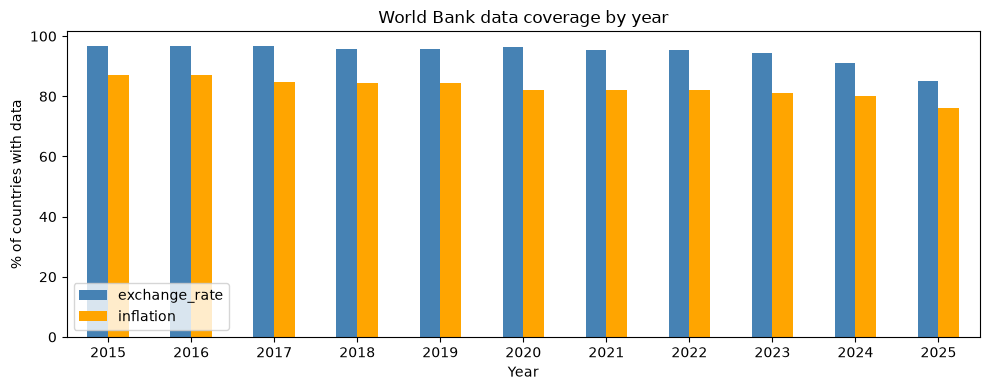

In [14]:
import matplotlib.pyplot as plt

coverage = per_year / len(real) * 100
coverage.plot(kind="bar", figsize=(10, 4), color=["steelblue", "orange"])
plt.ylabel("% of countries with data")
plt.xlabel("Year")
plt.title("World Bank data coverage by year")
plt.xticks(rotation=0)
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

Exchange rate is available for about 95% of countries every year until 2023, inflation for about 85%.
In 2025 it is less (185 and 165 countries), because the World Bank has not added all values yet.

In [15]:
fx_raw = wb_real[wb_real["indicator"] == "exchange_rate"]
has_fx = fx_raw.dropna(subset=["value"])["iso3"].unique()
no_fx = real[~real["iso3"].isin(has_fx)]
print("countries without any exchange rate:", len(no_fx))
print(list(no_fx["name"]))

countries without any exchange rate: 5
['Cuba', "Korea, Dem. People's Rep.", 'West Bank and Gaza', 'Turkmenistan', 'British Virgin Islands']


These 5 have no exchange rate at all: closed economies (North Korea, Turkmenistan, Cuba)
or places that use the currency of another country (Palestine uses the shekel, British Virgin Islands use USD).

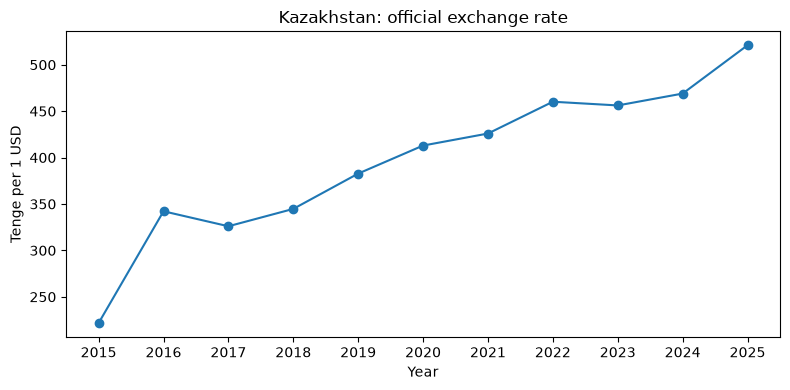

In [16]:
kz = ex[ex["iso3"] == "KAZ"].sort_values("year")

plt.figure(figsize=(8, 4))
plt.plot(kz["year"].astype(int), kz["value"], marker="o")
plt.xticks(range(2015, 2026))
plt.xlabel("Year")
plt.ylabel("Tenge per 1 USD")
plt.title("Kazakhstan: official exchange rate")
plt.tight_layout()
plt.show()

The tenge was about 222 per USD in 2015 and about 342 in 2016 (in August 2015 the tenge started to float).
After that it slowly became weaker, to about 521 in 2025.

What we noticed:
- there are not only countries but also groups like "World", "Euro area", "Low income" (region = "Aggregates")
- a lot of missing values, especially for 2025
- `year` is a string

We leave this for Part 3 (cleaning) and just save the raw data.

### Files we save

`data/wb_countries_raw.csv` - one row per country or group

| Column | Meaning |
|---|---|
| iso3 | ISO code of the country (KAZ, DEU, ...) |
| name | name used by the World Bank |
| region | region, or "Aggregates" for groups |
| income_level | World Bank income group |

`data/wb_indicators_raw.csv` - one row = country + year + indicator

| Column | Meaning |
|---|---|
| iso3 | ISO code |
| name | country name |
| year | year (2015-2025) |
| indicator | `exchange_rate` or `inflation` |
| value | the number (empty if no data) |

In [17]:
countries.to_csv("data/wb_countries_raw.csv", index=False)
wb.to_csv("data/wb_indicators_raw.csv", index=False)
print("saved")

saved


# Part 2. Web scraping GDP from Wikipedia
Author: **Kalybay Nurdaulet**

Page: https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)

The table has GDP of every country in millions of USD from IMF, World Bank and UN.
We use `requests` + `BeautifulSoup`.

Result: `data/gdp_raw.csv`

## About the data

**What is nominal GDP:** gross domestic product = the value of all goods and services produced in a country in one year.
"Nominal" means it is in current prices and converted to US dollars with the current exchange rate
(not adjusted for inflation or price levels). We use it as a measure of **how big the economy is**.

**What is in the table:** one row per country or territory, and GDP from three organisations:

| Column on the page | Source | What it is |
|---|---|---|
| Country/Territory | - | name of the country (sometimes with footnotes) |
| IMF (year) | International Monetary Fund, World Economic Outlook | IMF estimate, the newest one |
| World Bank (year) | World Bank | value from the World Bank |
| United Nations (year) | UN Statistics Division | value from the UN |

- All numbers are in **millions of US dollars**.
- The year of each source is written in the column name (IMF is usually an estimate for the current year).
- If a source has only an older value, the year is written in brackets, for example "407,786 (2025)".
- If a source has no data, it is written "— N/a".
- The table also has territories (Hong Kong, Puerto Rico, Greenland...) and a "World" row at the top.

**Why Wikipedia:** the page collects the three official sources in one table, so it is easy to compare them.
The page has a second table with regions (G7, EU...), we do not need it.

In [18]:
import os
import requests
import pandas as pd
from bs4 import BeautifulSoup
from urllib.robotparser import RobotFileParser

os.makedirs("data", exist_ok=True)

URL = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)"
HEADERS = {"User-Agent": "SIS1 student project"}

### Checking robots.txt
Wikipedia blocks the default python user agent, so we download robots.txt with requests and then give it to the parser.

In [19]:
robots_text = requests.get("https://en.wikipedia.org/robots.txt", headers=HEADERS).text
rp = RobotFileParser()
rp.parse(robots_text.splitlines())
print("can we scrape this page?", rp.can_fetch(HEADERS["User-Agent"], URL))

can we scrape this page? True


### Downloading the page

In [20]:
response = requests.get(URL, headers=HEADERS)
print(response.status_code)

soup = BeautifulSoup(response.text, "html.parser")
tables = soup.find_all("table", class_="wikitable")
print("number of tables:", len(tables))

200
number of tables: 2


The first table is the one with countries. We take the header row and then go through all other rows.

In [21]:
table = tables[0]
all_rows = table.find_all("tr")

header = []
for cell in all_rows[0].find_all(["th", "td"]):
    header.append(cell.get_text(" ", strip=True))
print(header)

data = []
for row in all_rows[1:]:
    cells = row.find_all(["th", "td"])
    values = [c.get_text(" ", strip=True) for c in cells]
    if len(values) == len(header):
        data.append(values)

gdp = pd.DataFrame(data, columns=header)
print(gdp.shape)
gdp.head(10)

['Country/Territory', 'IMF ( 2026 ) [ 1 ]', 'World Bank (2025) [ 6 ]', 'United Nations (2024) [ 7 ]']
(222, 4)


,Country/Territory,IMF ( 2026 ) [ 1 ],World Bank (2025) [ 6 ],United Nations (2024) [ 7 ]
0,World,"126,295,331","118,350,166","111,565,144"
1,United States,"32,383,920","30,769,700","29,298,000"
2,China [ n 1 ],"20,851,593","19,498,039","18,743,802"
3,Germany,"5,452,858","5,050,923","4,659,929"
4,Japan,"4,379,253","4,435,163","4,026,211"
5,United Kingdom,"4,264,794","4,002,588","3,685,881"
6,India,"4,153,191","3,956,067","3,952,244"
7,France,"3,596,094","3,366,316","3,160,443"
8,Italy,"2,738,164","2,551,557","2,380,825"
9,Russia,"2,656,452","2,561,310","2,173,386"


### Problems in the data

In [22]:
# rows with footnotes [..], N/a or a year in brackets
problems = gdp[gdp.apply(lambda row: row.str.contains(r"N/a|\(|\[").any(), axis=1)]
print(len(problems))
problems.head(10)

47


,Country/Territory,IMF ( 2026 ) [ 1 ],World Bank (2025) [ 6 ],United Nations (2024) [ 7 ]
2,China [ n 1 ],"20,851,593","19,498,039","18,743,802"
22,Taiwan [ n 3 ],"976,719",— N/a,— N/a
30,United Arab Emirates,"621,546","552,325 (2024)","552,325"
41,Hong Kong [ n 4 ],"450,138","427,310","406,863"
45,Pakistan,"407,786 (2025)","407,307","379,120"
57,Cuba,— N/a,"107,352 (2020)","252,063"
58,Ukraine [ n 5 ],"225,337","214,233","190,741"
81,Sri Lanka,"98,964 (2024)","108,825","98,714"
86,Tanzania [ n 6 ],"94,889","90,143","79,236"
98,Macau [ n 7 ],"54,228","52,061","49,467"


## Understanding the data

In [23]:
print("columns:", list(gdp.columns))
print("rows:", len(gdp))
print("first row:", gdp.iloc[0, 0], "(this is the total for the world)")

columns: ['Country/Territory', 'IMF ( 2026 ) [ 1 ]', 'World Bank (2025) [ 6 ]', 'United Nations (2024) [ 7 ]']
rows: 222
first row: World (this is the total for the world)


In [24]:
# how many values every source has
for col in gdp.columns[1:]:
    missing = gdp[col].str.contains("N/a").sum()
    old_year = gdp[col].str.contains(r"\(").sum()
    print(col)
    print("   has value:", len(gdp) - missing, "| N/a:", missing, "| older year in brackets:", old_year)

IMF ( 2026 ) [ 1 ]
   has value: 198 | N/a: 24 | older year in brackets: 7
World Bank (2025) [ 6 ]
   has value: 215 | N/a: 7 | older year in brackets: 28
United Nations (2024) [ 7 ]
   has value: 213 | N/a: 9 | older year in brackets: 0


IMF has the newest numbers but not for every territory, World Bank has the most values.
That is why later we take IMF first and use the others only when IMF is missing.

The biggest and the smallest economies in the table:

In [25]:
gdp.iloc[1:11]

,Country/Territory,IMF ( 2026 ) [ 1 ],World Bank (2025) [ 6 ],United Nations (2024) [ 7 ]
1,United States,"32,383,920","30,769,700","29,298,000"
2,China [ n 1 ],"20,851,593","19,498,039","18,743,802"
3,Germany,"5,452,858","5,050,923","4,659,929"
4,Japan,"4,379,253","4,435,163","4,026,211"
5,United Kingdom,"4,264,794","4,002,588","3,685,881"
6,India,"4,153,191","3,956,067","3,952,244"
7,France,"3,596,094","3,366,316","3,160,443"
8,Italy,"2,738,164","2,551,557","2,380,825"
9,Russia,"2,656,452","2,561,310","2,173,386"
10,Brazil,"2,635,912","2,279,920","2,185,822"


In [26]:
gdp.tail(5)

,Country/Territory,IMF ( 2026 ) [ 1 ],World Bank (2025) [ 6 ],United Nations (2024) [ 7 ]
217,Palau,377,345,310
218,Marshall Islands,342,308,281
219,Nauru,196,176,187
220,Montserrat,— N/a,— N/a,81
221,Tuvalu,65,57,56


The difference between the biggest (United States, ~32 trillion USD) and the smallest (tens of millions USD) is huge,
so in the analysis we will use log10(GDP).

Comparing the three sources for some countries:

In [27]:
gdp[gdp.iloc[:, 0].isin(["United States", "China", "Germany", "Kazakhstan", "Turkey", "Brazil"])]

,Country/Territory,IMF ( 2026 ) [ 1 ],World Bank (2025) [ 6 ],United Nations (2024) [ 7 ]
1,United States,"32,383,920","30,769,700","29,298,000"
3,Germany,"5,452,858","5,050,923","4,659,929"
10,Brazil,"2,635,912","2,279,920","2,185,822"
16,Turkey,"1,640,223","1,597,293","1,323,255"
49,Kazakhstan,"360,456","306,239","291,480"


The numbers are different because the sources are for different years and use a bit different methods,
but the order of countries is almost the same.
China is not in the result: on the page its name is "China [ n 1 ]" (with a footnote), so the exact name does not match.
This is one more reason why names must be cleaned in Part 3.

### How close are the three sources?
To compare them we quickly turn the text into numbers (only for this check, the real cleaning is in Part 3).

In [28]:
def to_number(x):
    x = x.split("(")[0].replace(",", "").strip()
    return float(x) if x.isdigit() else None

check = pd.DataFrame({
    "country": gdp.iloc[:, 0],
    "imf": gdp.iloc[:, 1].apply(to_number),
    "wb": gdp.iloc[:, 2].apply(to_number),
    "un": gdp.iloc[:, 3].apply(to_number),
}).iloc[1:]

both = check.dropna(subset=["imf", "wb"]).copy()
both["diff_pct"] = (both["imf"] - both["wb"]) / both["wb"] * 100
print("countries with IMF and World Bank value:", len(both))
print("difference IMF vs World Bank, %:")
print(both["diff_pct"].describe().round(1))

countries with IMF and World Bank value: 196
difference IMF vs World Bank, %:
count    196.0
mean      10.2
std       17.9
min      -65.6
25%        5.0
50%        9.0
75%       12.6
max      152.9
Name: diff_pct, dtype: float64


The median difference is about +9%: IMF is usually higher, because the IMF number is for a newer year.

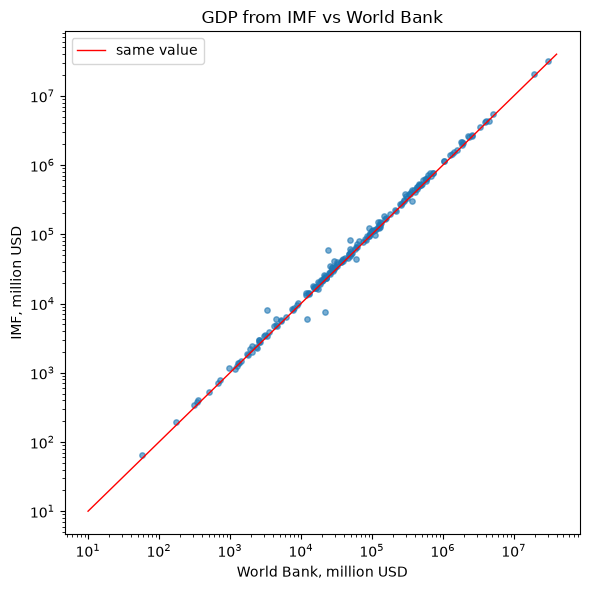

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(both["wb"], both["imf"], s=15, alpha=0.6)
plt.plot([10, 4e7], [10, 4e7], color="red", linewidth=1, label="same value")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("World Bank, million USD")
plt.ylabel("IMF, million USD")
plt.title("GDP from IMF vs World Bank")
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
# countries where the sources are the most different
both.reindex(both["diff_pct"].abs().sort_values(ascending=False).index).head(8).round(1)

,country,imf,wb,un,diff_pct
144,Syria,60043.0,23738.0,17254.0,152.9
164,Burundi,8137.0,3365.0,4431.0,141.8
89,Turkmenistan,83065.0,49829.0,68655.0,66.7
168,Yemen,7435.0,21606.0,14304.0,-65.6
172,South Sudan,6069.0,11998.0,3522.0,-49.4
110,Zambia,41243.0,28880.0,25303.0,42.8
71,DR Congo,123406.0,91031.0,75322.0,35.6
115,Lebanon,34497.0,25972.0,37990.0,32.8


The biggest differences are in countries with war or crisis (Syria, Yemen, South Sudan, Lebanon)
or with closed statistics (Turkmenistan). There GDP in dollars depends a lot on which exchange rate is used.
For most countries the sources are close, so taking IMF first is OK.

In [31]:
world = to_number(gdp.iloc[0, 1])
top10 = check.sort_values("imf", ascending=False).head(10)
print("top 10 economies:", list(top10["country"]))
print("share of world GDP:", round(top10["imf"].sum() / world * 100, 1), "%")

top 10 economies: ['United States', 'China [ n 1 ]', 'Germany', 'Japan', 'United Kingdom', 'India', 'France', 'Italy', 'Russia', 'Brazil']
share of world GDP: 65.8 %


The top 10 economies make about 66% of world GDP, so GDP is very uneven. This is one more reason to use log10(GDP).
(China is still written with the footnote here - names are cleaned in Part 3.)

What has to be cleaned later (Part 3):
- numbers are text with commas: "32,383,920"
- footnotes in names: "China [ n 1 ]"
- missing values are written as "— N/a"
- some numbers have an older year: "407,786 (2025)"
- the first row is "World", it is not a country
- names are not the same as in World Bank ("South Korea" vs "Korea, Rep.")

### File we save

`data/gdp_raw.csv` - the table exactly as it is on the page (all columns are text, not cleaned):

| Column | Meaning |
|---|---|
| Country/Territory | country name |
| IMF (...) | GDP from IMF, millions USD |
| World Bank (...) | GDP from World Bank, millions USD |
| United Nations (...) | GDP from UN, millions USD |

In [32]:
gdp.to_csv("data/gdp_raw.csv", index=False)
print("saved")

saved


# Part 3. Cleaning and merging
Author: **Dauirkhankyzy Balnur**

Input: files from Part 1 and Part 2.
Output:
- `data/fx_rates_clean.csv` - clean exchange rates (country, year, rate)
- `data/gdp_clean.csv` - clean GDP
- `data/merged_dataset.csv` - final table, one row per country
- `data/by_currency.csv` - one row per currency (for checking)

In [33]:
import re
import numpy as np
import pandas as pd

countries = pd.read_csv("data/wb_countries_raw.csv")
wb = pd.read_csv("data/wb_indicators_raw.csv")
gdp_raw = pd.read_csv("data/gdp_raw.csv", dtype=str)

print(countries.shape, wb.shape, gdp_raw.shape)

(296, 4) (5830, 5) (222, 4)


## 1. World Bank data
Remove groups (World, Euro area, ...) - in the country list they have region "Aggregates".

In [34]:
countries = countries[countries["region"] != "Aggregates"]
print("real countries:", len(countries))

wb = wb[wb["iso3"].isin(countries["iso3"])]
wb["year"] = wb["year"].astype(int)
print("rows left:", len(wb))
print("duplicates:", wb.duplicated(["iso3", "year", "indicator"]).sum())

real countries: 217
rows left: 4774
duplicates: 0


Make a table where rows are countries and columns are years.

In [35]:
fx = wb[wb["indicator"] == "exchange_rate"].pivot(index="iso3", columns="year", values="value")
infl = wb[wb["indicator"] == "inflation"].pivot(index="iso3", columns="year", values="value")
fx.head()

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
iso3,,,,,,,,,,,
ABW,1.790000,1.790000,1.790000,1.790000,1.790000,1.790000,1.790000,1.790000,1.790000,1.790000,1.790000
AFG,61.143462,67.866086,68.026904,72.083247,77.737949,76.813536,NaN,NaN,NaN,NaN,NaN
AGO,120.060702,163.656434,165.915951,252.855748,364.825805,578.258780,631.441956,460.567512,685.020238,869.846190,911.993038
ALB,125.961667,124.142500,119.100000,107.989167,109.850833,108.650000,103.520000,113.041667,100.645000,93.123333,NaN
AND,NaN,NaN,NaN,NaN,NaN,NaN,0.845377,0.950916,0.924710,0.924367,0.887144


## 2. Problems with exchange rates
1. Some countries have no data at all -> remove.
2. Some countries use the US dollar (rate is always 1) -> remove, the change vs USD is always 0.
3. Croatia changed kuna to euro in 2023, so the rate jumps from ~7 to ~0.9. We divide the old years by 7.5345 (official rate HRK/EUR).
4. Other countries where the rate fell more than 2 times in one year probably changed their currency -> remove.
5. We need 2015 and 2025 and at least 9 years of 11. Small gaps -> linear interpolation.

In [36]:
# 1
steps = [("in World Bank data", len(fx))]
print("no data:", fx.isna().all(axis=1).sum())
fx = fx.dropna(how="all")
steps.append(("has some data", len(fx)))

# 2
usd_countries = []
for iso in fx.index:
    values = fx.loc[iso].dropna()
    if iso == "USA" or (values.round(4) == 1).all():
        usd_countries.append(iso)
print("use USD:", usd_countries)
fx = fx.drop(usd_countries)
steps.append(("without USD countries", len(fx)))

# 3
old_years = [y for y in fx.columns if y < 2023]
fx.loc["HRV", old_years] = fx.loc["HRV", old_years] / 7.5345

# 4
ratio = fx / fx.shift(1, axis=1)
changed = ratio[(ratio < 0.5).any(axis=1)].index.tolist()
print("currency change:", changed)
fx = fx.drop(changed)
steps.append(("without currency change", len(fx)))

# 5
good = fx[2015].notna() & fx[2025].notna() & (fx.notna().sum(axis=1) >= 9)
fx = fx[good]
steps.append(("has 2015, 2025 and 9+ years", len(fx)))
print("countries left:", len(fx))
print("missing before:", fx.isna().sum().sum())
fx = fx.interpolate(axis=1)
print("missing after:", fx.isna().sum().sum())

no data: 5
use USD: ['ASM', 'BHS', 'BMU', 'ECU', 'FSM', 'GUM', 'MHL', 'MNP', 'PAN', 'PLW', 'PRI', 'SLV', 'TCA', 'TLS', 'USA', 'VIR']
currency change: ['ZWE']
countries left: 167
missing before: 1
missing after: 0


## 3. New columns for every country
- `value_change_pct` - how the value of the currency changed vs USD from 2015 to 2025: `(rate_2015 / rate_2025 - 1) * 100`. Negative = currency became weaker.
- `volatility_pct` - standard deviation of yearly changes
- `max_yearly_drop_pct` - worst year
- `avg_inflation_pct` - average inflation (only if there are at least 8 years)

In [37]:
# value of 1 unit of currency in dollars = 1 / rate
yearly_change = (1 / fx).pct_change(axis=1) * 100
yearly_change = yearly_change.drop(columns=2015)

features = pd.DataFrame()
features["rate_2015"] = fx[2015]
features["rate_2025"] = fx[2025]
features["value_change_pct"] = (fx[2015] / fx[2025] - 1) * 100
features["volatility_pct"] = yearly_change.std(axis=1)
features["max_yearly_drop_pct"] = yearly_change.min(axis=1)

infl_count = infl.notna().sum(axis=1)
features["avg_inflation_pct"] = infl.mean(axis=1)
features.loc[infl_count < 8, "avg_inflation_pct"] = np.nan

features = features.reset_index()
features = features.merge(countries, on="iso3", how="left")
features.sort_values("value_change_pct").head()

,iso3,rate_2015,rate_2025,value_change_pct,volatility_pct,max_yearly_drop_pct,avg_inflation_pct,name,region,income_level
3,ARG,9.233186,1240.851250,-99.255899,16.248679,-67.611272,NaN,Argentina,Latin America & Caribbean,Upper middle income
92,LBN,1507.500000,89500.000000,-98.315642,36.621196,-89.135625,63.716312,Lebanon,"Middle East, North Africa, Afghanistan & Pakistan",Lower middle income
156,TUR,2.720009,39.454813,-93.106016,10.313193,-46.519535,28.139172,Turkiye,Europe & Central Asia,Upper middle income
143,SUR,3.416667,37.260179,-90.830246,19.779844,-48.957094,34.197901,Suriname,Latin America & Caribbean,Upper middle income
118,NGA,192.440333,1518.380948,-87.325952,17.740313,-56.375304,17.696130,Nigeria,Sub-Saharan Africa,Lower middle income


## 4. Cleaning GDP

In [38]:
gdp = gdp_raw.copy()
gdp.columns = ["country", "gdp_imf", "gdp_wb", "gdp_un"]

def clean_name(name):
    # "China [ n 1 ]" -> "China"
    return re.sub(r"\[.*?\]", "", name).strip()

def clean_number(x):
    # "407,786 (2025)" -> 407786.0 ;  "— N/a" -> NaN
    x = re.sub(r"\(.*?\)", "", str(x))
    x = re.sub(r"\[.*?\]", "", x)
    x = x.replace(",", "").strip()
    if x.isdigit():
        return float(x)
    return np.nan

gdp["country"] = gdp["country"].apply(clean_name)
for col in ["gdp_imf", "gdp_wb", "gdp_un"]:
    gdp[col] = gdp[col].apply(clean_number)

gdp = gdp[gdp["country"] != "World"]
print("duplicates:", gdp["country"].duplicated().sum())
print(gdp.isna().sum())

duplicates: 0
country     0
gdp_imf    24
gdp_wb      7
gdp_un      9
dtype: int64


We take IMF GDP. If IMF is missing we take World Bank, then UN. Then convert millions to billions.

In [39]:
gdp["gdp_usd_bn"] = gdp["gdp_imf"].fillna(gdp["gdp_wb"]).fillna(gdp["gdp_un"]) / 1000

def which_source(row):
    if pd.notna(row["gdp_imf"]):
        return "IMF"
    if pd.notna(row["gdp_wb"]):
        return "World Bank"
    return "UN"

gdp["gdp_source"] = gdp.apply(which_source, axis=1)
gdp = gdp.dropna(subset=["gdp_usd_bn"]).sort_values("gdp_usd_bn", ascending=False)
gdp["gdp_rank"] = range(1, len(gdp) + 1)

print(len(gdp))
print(gdp["gdp_source"].value_counts())
gdp.head(10)

221
gdp_source
IMF           197
World Bank     18
UN              6
Name: count, dtype: int64


,country,gdp_imf,gdp_wb,gdp_un,gdp_usd_bn,gdp_source,gdp_rank
1,United States,32383920.0,30769700.0,29298000.0,32383.920,IMF,1
2,China,20851593.0,19498039.0,18743802.0,20851.593,IMF,2
3,Germany,5452858.0,5050923.0,4659929.0,5452.858,IMF,3
4,Japan,4379253.0,4435163.0,4026211.0,4379.253,IMF,4
5,United Kingdom,4264794.0,4002588.0,3685881.0,4264.794,IMF,5
6,India,4153191.0,3956067.0,3952244.0,4153.191,IMF,6
7,France,3596094.0,3366316.0,3160443.0,3596.094,IMF,7
8,Italy,2738164.0,2551557.0,2380825.0,2738.164,IMF,8
9,Russia,2656452.0,2561310.0,2173386.0,2656.452,IMF,9
10,Brazil,2635912.0,2279920.0,2185822.0,2635.912,IMF,10


## 5. Merging
We merge by country name, but World Bank and Wikipedia write some names differently.
First let's find which names do not match.

In [40]:
not_matched = sorted(set(countries["name"]) - set(gdp["country"]))
print(len(not_matched))
print(not_matched)

37
['Bahamas, The', 'Brunei Darussalam', 'Cabo Verde', 'Congo, Dem. Rep.', 'Congo, Rep.', "Cote d'Ivoire", 'Curacao', 'Czechia', 'Egypt, Arab Rep.', 'Gambia, The', 'Gibraltar', 'Hong Kong SAR, China', 'Iran, Islamic Rep.', "Korea, Dem. People's Rep.", 'Korea, Rep.', 'Kyrgyz Republic', 'Lao PDR', 'Macao SAR, China', 'Micronesia, Fed. Sts.', 'Naoero', 'Puerto Rico (US)', 'Russian Federation', 'Sao Tome and Principe', 'Sint Maarten (Dutch part)', 'Slovak Republic', 'Somalia, Fed. Rep.', 'St. Kitts and Nevis', 'St. Lucia', 'St. Martin (French part)', 'St. Vincent and the Grenadines', 'Syrian Arab Republic', 'Turkiye', 'Venezuela, RB', 'Viet Nam', 'Virgin Islands (U.S.)', 'West Bank and Gaza', 'Yemen, Rep.']


We fix them by hand with a dictionary (World Bank name -> Wikipedia name).

In [41]:
names = {
    "Bahamas, The": "Bahamas", "Brunei Darussalam": "Brunei", "Cabo Verde": "Cape Verde",
    "Congo, Dem. Rep.": "DR Congo", "Congo, Rep.": "Congo", "Cote d'Ivoire": "Ivory Coast",
    "Curacao": "Curaçao", "Czechia": "Czech Republic", "Egypt, Arab Rep.": "Egypt",
    "Gambia, The": "Gambia", "Hong Kong SAR, China": "Hong Kong", "Iran, Islamic Rep.": "Iran",
    "Korea, Dem. People's Rep.": "North Korea", "Korea, Rep.": "South Korea",
    "Kyrgyz Republic": "Kyrgyzstan", "Lao PDR": "Laos", "Macao SAR, China": "Macau",
    "Micronesia, Fed. Sts.": "Federated States of Micronesia", "Naoero": "Nauru",
    "Puerto Rico (US)": "Puerto Rico", "Russian Federation": "Russia",
    "Sao Tome and Principe": "São Tomé and Príncipe", "Sint Maarten (Dutch part)": "Sint Maarten",
    "Slovak Republic": "Slovakia", "Somalia, Fed. Rep.": "Somalia",
    "St. Kitts and Nevis": "Saint Kitts and Nevis", "St. Lucia": "Saint Lucia",
    "St. Martin (French part)": "Saint Martin",
    "St. Vincent and the Grenadines": "Saint Vincent and the Grenadines",
    "Syrian Arab Republic": "Syria", "Turkiye": "Turkey", "Venezuela, RB": "Venezuela",
    "Viet Nam": "Vietnam", "Virgin Islands (U.S.)": "U.S. Virgin Islands",
    "West Bank and Gaza": "Palestine", "Yemen, Rep.": "Yemen",
}

features["country"] = features["name"].replace(names)
print("still not found:", sorted(set(countries["name"].replace(names)) - set(gdp["country"])))

still not found: ['Gibraltar']


In [42]:
merged = features.merge(gdp[["country", "gdp_usd_bn", "gdp_rank", "gdp_source"]], on="country", how="inner")
merged["log10_gdp"] = np.log10(merged["gdp_usd_bn"])
merged = merged.sort_values("gdp_usd_bn", ascending=False)

merged = merged[["iso3", "country", "region", "income_level", "gdp_usd_bn", "log10_gdp", "gdp_rank",
                 "rate_2015", "rate_2025", "value_change_pct", "volatility_pct",
                 "max_yearly_drop_pct", "avg_inflation_pct", "gdp_source"]]

print("before merge:", len(features), "after merge:", len(merged))
print("duplicates:", merged["country"].duplicated().sum())
print(merged.isna().sum())
merged.head(10)

before merge: 167 after merge: 166
duplicates: 0
iso3                    0
country                 0
region                  0
income_level            0
gdp_usd_bn              0
log10_gdp               0
gdp_rank                0
rate_2015               0
rate_2025               0
value_change_pct        0
volatility_pct          0
max_yearly_drop_pct     0
avg_inflation_pct      20
gdp_source              0
dtype: int64


,iso3,country,region,income_level,gdp_usd_bn,log10_gdp,gdp_rank,rate_2015,rate_2025,value_change_pct,volatility_pct,max_yearly_drop_pct,avg_inflation_pct,gdp_source
30,CHN,China,East Asia & Pacific,Upper middle income,20851.593,4.319139,2,6.227489,7.189847,-13.384967,3.947792,-6.275725,1.444612,IMF
43,DEU,Germany,Europe & Central Asia,High income,5452.858,3.736624,3,0.901296,0.884969,1.844976,4.883245,-10.965355,2.377485,IMF
83,JPN,Japan,East Asia & Pacific,High income,4379.253,3.641400,4,121.044026,149.657927,-19.119536,7.340701,-16.535456,1.275331,IMF
58,GBR,United Kingdom,Europe & Central Asia,High income,4264.794,3.629898,5,0.654545,0.759474,-13.815942,6.246983,-11.623681,3.031244,IMF
76,IND,India,South Asia,Lower middle income,4153.191,3.618382,6,64.151944,87.158448,-26.396183,2.872647,-5.962099,4.755146,IMF
55,FRA,France,Europe & Central Asia,High income,3596.094,3.555831,7,0.901296,0.884969,1.844976,4.883245,-10.965355,1.761325,IMF
80,ITA,Italy,Europe & Central Asia,High income,2738.164,3.437459,8,0.901296,0.884969,1.844976,4.883245,-10.965355,1.908513,IMF
20,BRA,Brazil,Latin America & Caribbean,Upper middle income,2635.912,3.420931,10,3.326904,5.587286,-40.455809,9.308049,-23.485271,5.762233,IMF
26,CAN,Canada,North America,High income,2507.340,3.399213,11,1.278786,1.398106,-8.534366,3.291947,-3.663148,2.510571,IMF
6,AUS,Australia,East Asia & Pacific,High income,2123.963,3.327147,12,1.331090,1.551998,-14.233758,4.860968,-7.660604,2.745337,IMF


## 6. One row per currency
Many countries have the same currency (20 euro countries, CFA franc in Africa). Their rows are the same,
so they can change the correlations. We group countries with the same value change and volatility
(= same currency, or currencies fixed to the same thing, like all currencies fixed to USD)
and sum their GDP. Part 4 uses this to check the results.

In [43]:
merged["key"] = merged["value_change_pct"].round(3).astype(str) + "_" + merged["volatility_pct"].round(3).astype(str)

by_currency = merged.groupby("key").agg(
    country=("country", "first"),
    n_countries=("country", "count"),
    gdp_usd_bn=("gdp_usd_bn", "sum"),
    value_change_pct=("value_change_pct", "first"),
    volatility_pct=("volatility_pct", "first"),
    max_yearly_drop_pct=("max_yearly_drop_pct", "first"),
    avg_inflation_pct=("avg_inflation_pct", "mean"),
).reset_index(drop=True)
by_currency["log10_gdp"] = np.log10(by_currency["gdp_usd_bn"])
merged = merged.drop(columns="key")

print("countries:", len(merged), " currencies:", len(by_currency))
by_currency.sort_values("n_countries", ascending=False).head()

countries: 166  currencies: 99


,country,n_countries,gdp_usd_bn,value_change_pct,volatility_pct,max_yearly_drop_pct,avg_inflation_pct,log10_gdp
84,Germany,22,19200.477,1.844976,4.883245,-10.965355,2.612467,4.283312
74,Saudi Arabia,20,2583.661,0.000000,0.000000,0.000000,1.631144,3.412236
80,Ivory Coast,18,450.117,1.595250,4.917519,-11.098669,2.494399,2.653325
13,Australia,4,2124.625,-14.233758,4.860968,-7.660604,2.537026,3.327282
81,Denmark,3,511.152,1.602002,4.956063,-11.150676,1.814753,2.708550


## 7. Checks
How many countries we lost on every step:

In [44]:
steps.append(("merged with GDP", len(merged)))
funnel = pd.DataFrame(steps, columns=["step", "countries"])
funnel

,step,countries
0,in World Bank data,217
1,has some data,212
2,without USD countries,196
3,without currency change,195
4,"has 2015, 2025 and 9+ years",167
5,merged with GDP,166


From 217 countries 166 are left. Most were removed by the rule "2015, 2025 and at least 9 years" (28 countries)
and because they use the US dollar (16).

In [45]:
lost = features[~features["iso3"].isin(merged["iso3"])]
print("lost in the merge:", list(lost["name"]))

lost in the merge: ['Gibraltar']


Only Gibraltar was lost in the merge, it is not in the Wikipedia table.

Simple checks that the final table is OK. If something is wrong, `assert` stops the notebook.

In [46]:
assert merged["iso3"].is_unique
assert merged["country"].is_unique
assert (merged["rate_2015"] > 0).all() and (merged["rate_2025"] > 0).all()
assert merged[["gdp_usd_bn", "value_change_pct", "volatility_pct", "max_yearly_drop_pct"]].notna().all().all()
assert fx.notna().all().all()
assert (by_currency["n_countries"] >= 1).all()
print("all checks passed")

all checks passed


### Final table `data/merged_dataset.csv` (one row per country)

| Column | Meaning |
|---|---|
| iso3 | ISO code |
| country | country name (Wikipedia version) |
| region, income_level | from the World Bank |
| gdp_usd_bn | nominal GDP, billion USD |
| log10_gdp | log10 of GDP |
| gdp_rank | place by GDP |
| rate_2015, rate_2025 | local currency per 1 USD |
| value_change_pct | change of currency value vs USD 2015-2025, % |
| volatility_pct | std of yearly changes, % |
| max_yearly_drop_pct | worst year, % |
| avg_inflation_pct | average inflation 2015-2025, % (empty if less than 8 years) |
| gdp_source | IMF, World Bank or UN |

## 8. Saving

In [47]:
fx_long = fx.stack().reset_index()
fx_long.columns = ["iso3", "year", "rate_per_usd"]

fx_long.to_csv("data/fx_rates_clean.csv", index=False)
gdp.to_csv("data/gdp_clean.csv", index=False)
merged.to_csv("data/merged_dataset.csv", index=False)
by_currency.to_csv("data/by_currency.csv", index=False)
print("saved")

saved


# Part 4. Analysis and visualization
Author: **Abibulla Kundyz**

Input: `data/merged_dataset.csv`, `data/by_currency.csv`, `data/fx_rates_clean.csv` (from Part 3).

Questions:
1. How did currencies change against USD in 2015-2025?
2. Do bigger economies have more stable currencies?
3. Is GDP or inflation more connected to the loss of currency value?

In [48]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid")

df = pd.read_csv("data/merged_dataset.csv")
by_currency = pd.read_csv("data/by_currency.csv")
fx = pd.read_csv("data/fx_rates_clean.csv").pivot(index="iso3", columns="year", values="rate_per_usd")
print(df.shape, by_currency.shape, fx.shape)

(166, 14) (99, 8) (167, 11)


## Descriptive statistics

In [49]:
cols = ["gdp_usd_bn", "value_change_pct", "volatility_pct", "max_yearly_drop_pct", "avg_inflation_pct"]
df[cols].describe().round(2)

,gdp_usd_bn,value_change_pct,volatility_pct,max_yearly_drop_pct,avg_inflation_pct
count,166.00,166.00,166.00,166.00,146.00
mean,528.85,-14.36,5.26,-12.00,4.89
std,1816.00,25.11,4.73,12.96,6.91
min,0.06,-99.26,0.00,-89.14,0.29
25%,10.45,-24.76,2.93,-11.62,1.99
50%,52.01,0.00,4.88,-10.97,2.80
75%,380.83,1.60,5.84,-5.68,4.74
max,20851.59,23.49,36.62,0.00,63.72


In [50]:
show = ["country", "income_level", "gdp_usd_bn", "value_change_pct", "avg_inflation_pct"]
print("lost the most:")
print(df.sort_values("value_change_pct").head(8)[show].round(1).to_string(index=False))
print()
print("gained the most:")
print(df.sort_values("value_change_pct", ascending=False).head(5)[show].round(1).to_string(index=False))

lost the most:
   country        income_level  gdp_usd_bn  value_change_pct  avg_inflation_pct
 Argentina Upper middle income       688.4             -99.3                NaN
   Lebanon Lower middle income        34.5             -98.3               63.7
    Turkey Upper middle income      1640.2             -93.1               28.1
  Suriname Upper middle income         5.9             -90.8               34.2
   Nigeria Lower middle income       377.4             -87.3               17.7
    Angola Lower middle income       152.4             -86.8               21.6
     Egypt Lower middle income       429.6             -84.4               16.1
Uzbekistan Lower middle income       181.5             -79.6               11.5

gained the most:
       country        income_level  gdp_usd_bn  value_change_pct  avg_inflation_pct
       Armenia Upper middle income        31.9              23.5                2.7
 Liechtenstein         High income         9.4              15.8               

In [51]:
weaker = (df["value_change_pct"] < 0).sum()
print("weaker vs USD:", weaker, "of", len(df))

# volatility close to 0 = currency is fixed to the dollar
pegged = df[df["volatility_pct"] < 0.5]
print("fixed to USD:", len(pegged), list(pegged["country"].head(6)))
not_pegged = df[df["volatility_pct"] >= 0.5]
print("weaker among the others:", round((not_pegged["value_change_pct"] < 0).mean() * 100), "%")

weaker vs USD: 81 of 166
fixed to USD: 24 ['Saudi Arabia', 'United Arab Emirates', 'Hong Kong', 'Qatar', 'Oman', 'Bolivia']
weaker among the others: 54 %


In [52]:
order = ["High income", "Upper middle income", "Lower middle income", "Low income"]
income = df.groupby("income_level")[["value_change_pct", "volatility_pct", "avg_inflation_pct"]].median()
income = income.loc[order]
income["n"] = df["income_level"].value_counts()
income.to_csv("data/income_group_summary.csv")
income.round(2)

,value_change_pct,volatility_pct,avg_inflation_pct,n
income_level,,,,
High income,1.60,4.88,2.23,71
Upper middle income,-13.01,4.88,3.63,48
Lower middle income,-26.39,4.92,4.60,34
Low income,1.60,4.92,2.89,13


## Correlations
We mostly use Spearman because there are big outliers (Argentina, Lebanon, Turkey), and Spearman works with ranks.
GDP is very uneven, so we use log10(GDP).

In [53]:
corr_cols = ["log10_gdp", "value_change_pct", "volatility_pct", "max_yearly_drop_pct", "avg_inflation_pct"]
spearman = df[corr_cols].corr(method="spearman")
pearson = df[corr_cols].corr(method="pearson")
spearman_cur = by_currency[corr_cols].corr(method="spearman")

result = pd.DataFrame({
    "spearman": spearman["log10_gdp"],
    "pearson": pearson["log10_gdp"],
    "spearman (by currency)": spearman_cur["log10_gdp"],
}).drop("log10_gdp")
spearman.to_csv("data/correlations_spearman.csv")
result.round(3)

,spearman,pearson,spearman (by currency)
value_change_pct,-0.044,-0.138,0.032
volatility_pct,0.216,0.174,0.143
max_yearly_drop_pct,-0.209,-0.182,-0.115
avg_inflation_pct,0.029,0.002,-0.159


In [54]:
print("inflation vs value change:", round(spearman.loc["avg_inflation_pct", "value_change_pct"], 2))
print("inflation vs volatility:  ", round(spearman.loc["avg_inflation_pct", "volatility_pct"], 2))

inflation vs value change: -0.65
inflation vs volatility:   0.52


### Are the correlations significant?
With p-value from `scipy`. If p < 0.05 we say the connection is not random.

In [55]:
from scipy.stats import spearmanr

pairs = [("log10_gdp", "value_change_pct"), ("log10_gdp", "volatility_pct"),
         ("log10_gdp", "max_yearly_drop_pct"), ("avg_inflation_pct", "value_change_pct"),
         ("avg_inflation_pct", "volatility_pct")]

def test_pairs(data):
    rows = []
    for a, b in pairs:
        d = data.dropna(subset=[a, b])
        rho, p = spearmanr(d[a], d[b])
        rows.append({"x": a, "y": b, "n": len(d), "spearman": round(rho, 3), "p_value": round(p, 4)})
    return pd.DataFrame(rows)

test_pairs(df)

,x,y,n,spearman,p_value
0,log10_gdp,value_change_pct,166,-0.044,0.5758
1,log10_gdp,volatility_pct,166,0.216,0.0051
2,log10_gdp,max_yearly_drop_pct,166,-0.209,0.0069
3,avg_inflation_pct,value_change_pct,146,-0.646,0.0000
4,avg_inflation_pct,volatility_pct,146,0.523,0.0000


- GDP vs value change: p = 0.58, there is **no** connection.
- GDP vs volatility and GDP vs worst year: p < 0.01, the connection is weak but not random.
- Inflation: strong connection with both, p < 0.001.

### Check without fixed currencies
Fixed currencies have almost 0 change and 0 volatility, so they can hide the real connection.
We repeat the test only for floating currencies (volatility >= 0.5).

In [56]:
print("floating currencies:", len(not_pegged))
test_pairs(not_pegged)

floating currencies: 142


,x,y,n,spearman,p_value
0,log10_gdp,value_change_pct,142,-0.016,0.8459
1,log10_gdp,volatility_pct,142,0.093,0.2712
2,log10_gdp,max_yearly_drop_pct,142,-0.079,0.3498
3,avg_inflation_pct,value_change_pct,126,-0.736,0.0000
4,avg_inflation_pct,volatility_pct,126,0.366,0.0000


Without fixed currencies GDP vs volatility becomes 0.09 (p = 0.27), not significant.
So the small connection before was only because many small countries fix their currency.
The connection with inflation becomes even stronger (-0.74).

## Plots
### 1. Distribution of the value change

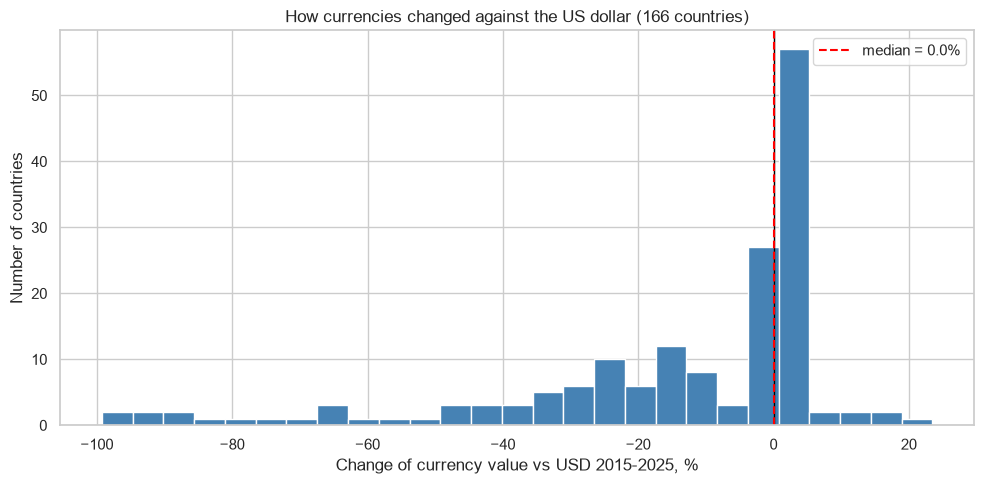

In [57]:
plt.figure(figsize=(10, 5))
plt.hist(df["value_change_pct"], bins=27, color="steelblue", edgecolor="white")
plt.axvline(0, color="black", linewidth=1)
plt.axvline(df["value_change_pct"].median(), color="red", linestyle="--",
            label="median = " + str(round(df["value_change_pct"].median(), 1)) + "%")
plt.xlabel("Change of currency value vs USD 2015-2025, %")
plt.ylabel("Number of countries")
plt.title("How currencies changed against the US dollar (" + str(len(df)) + " countries)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/1_value_change_hist.png", dpi=150)
plt.show()

Many countries are at 0 - these currencies are fixed to the dollar or euro. The rest mostly lost value, some almost 100%.

### 2. Currencies of big economies over time
2015 = 100. Lower than 100 means the currency became weaker.

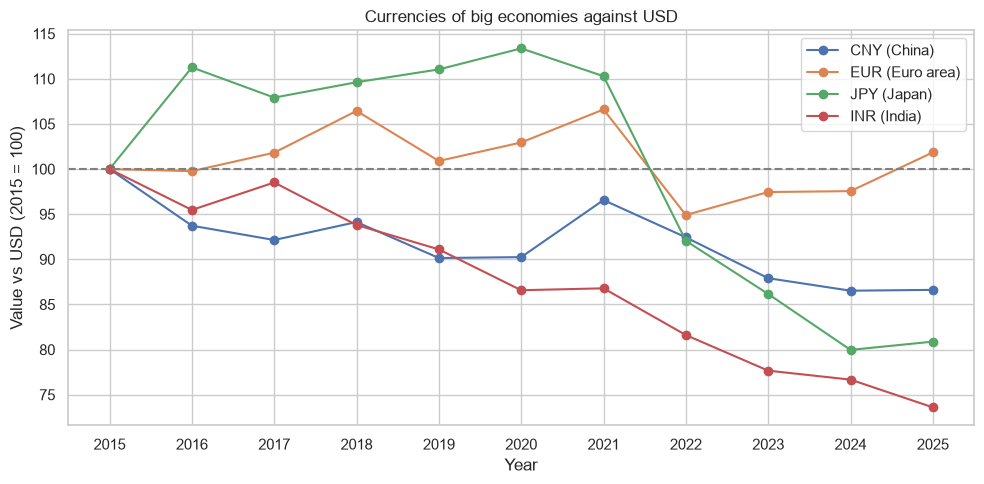

In [58]:
big = {"CHN": "CNY (China)", "DEU": "EUR (Euro area)", "JPN": "JPY (Japan)", "IND": "INR (India)"}

plt.figure(figsize=(10, 5))
for iso, label in big.items():
    value = 1 / fx.loc[iso]
    index = value / value[2015] * 100
    plt.plot(index.index, index.values, marker="o", label=label)
plt.axhline(100, color="gray", linestyle="--")
plt.xticks(range(2015, 2026))
plt.xlabel("Year")
plt.ylabel("Value vs USD (2015 = 100)")
plt.title("Currencies of big economies against USD")
plt.legend()
plt.tight_layout()
plt.savefig("figures/2_large_economies_index.png", dpi=150)
plt.show()

### 3. GDP vs value change and GDP vs volatility

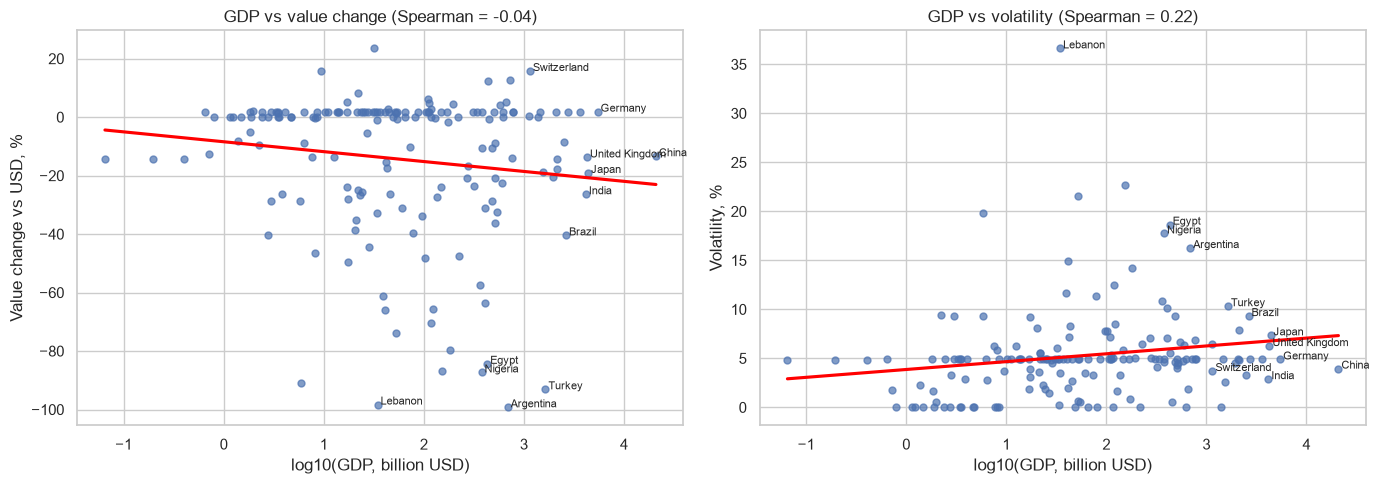

In [59]:
to_label = ["China", "Germany", "Japan", "India", "United Kingdom", "Brazil", "Turkey",
            "Argentina", "Switzerland", "Nigeria", "Egypt", "Lebanon"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, name, short in [(axes[0], "value_change_pct", "Value change vs USD, %", "value change"),
                             (axes[1], "volatility_pct", "Volatility, %", "volatility")]:
    sns.regplot(data=df, x="log10_gdp", y=col, ax=ax, ci=None,
                scatter_kws={"s": 25, "alpha": 0.7}, line_kws={"color": "red"})
    for _, row in df[df["country"].isin(to_label)].iterrows():
        ax.text(row["log10_gdp"] + 0.03, row[col], row["country"], fontsize=8)
    rho = spearman.loc["log10_gdp", col]
    ax.set_title("GDP vs " + short + " (Spearman = " + str(round(rho, 2)) + ")")
    ax.set_xlabel("log10(GDP, billion USD)")
    ax.set_ylabel(name)
plt.tight_layout()
plt.savefig("figures/3_gdp_scatter.png", dpi=150)
plt.show()

The line for value change is almost flat, so GDP does not really explain it. Volatility is even a bit higher for big economies -
small countries often fix their currency.

### 4. Inflation vs value change
Some countries have very high inflation, so the x axis is in log scale (symlog).

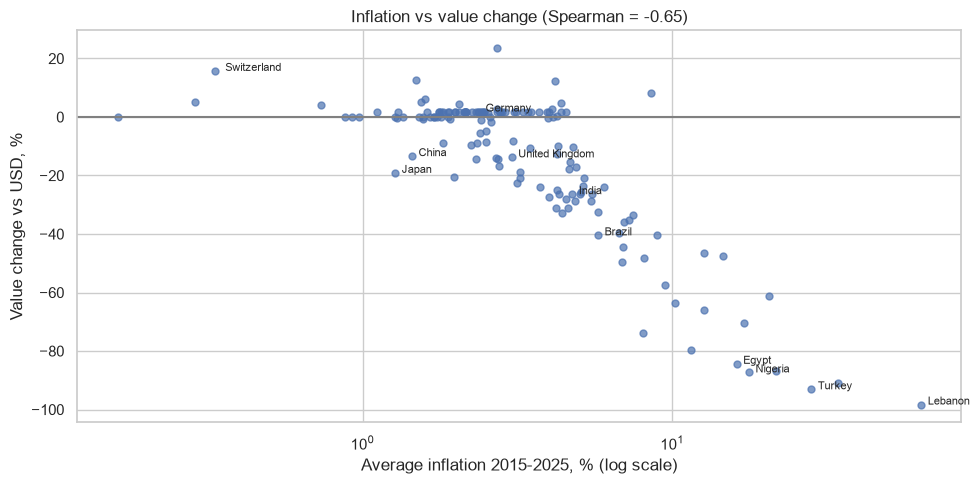

In [60]:
d = df.dropna(subset=["avg_inflation_pct"])

plt.figure(figsize=(10, 5))
plt.scatter(d["avg_inflation_pct"], d["value_change_pct"], s=25, alpha=0.7)
for _, row in d[d["country"].isin(to_label)].iterrows():
    plt.text(row["avg_inflation_pct"] * 1.05, row["value_change_pct"], row["country"], fontsize=8)
plt.xscale("symlog", linthresh=1)
plt.axhline(0, color="gray")
rho = spearman.loc["avg_inflation_pct", "value_change_pct"]
plt.title("Inflation vs value change (Spearman = " + str(round(rho, 2)) + ")")
plt.xlabel("Average inflation 2015-2025, % (log scale)")
plt.ylabel("Value change vs USD, %")
plt.tight_layout()
plt.savefig("figures/4_inflation_vs_change.png", dpi=150)
plt.show()

Here the connection is clear: higher inflation -> bigger loss of value.

### 5. Value change by income group

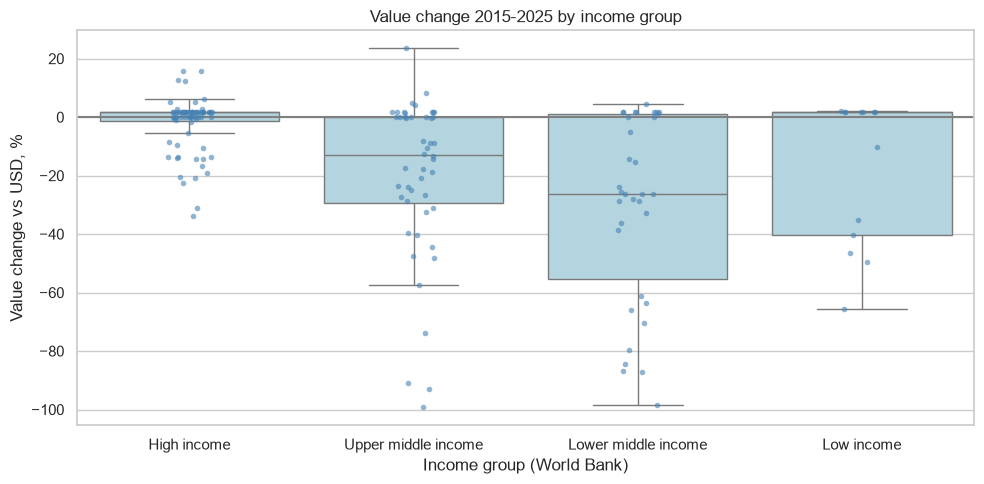

In [61]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="income_level", y="value_change_pct", order=order, color="lightblue", showfliers=False)
sns.stripplot(data=df, x="income_level", y="value_change_pct", order=order, color="steelblue", size=4, alpha=0.6)
plt.axhline(0, color="gray")
plt.xlabel("Income group (World Bank)")
plt.ylabel("Value change vs USD, %")
plt.title("Value change 2015-2025 by income group")
plt.tight_layout()
plt.savefig("figures/5_income_boxplot.png", dpi=150)
plt.show()

### 6. Correlation heatmap

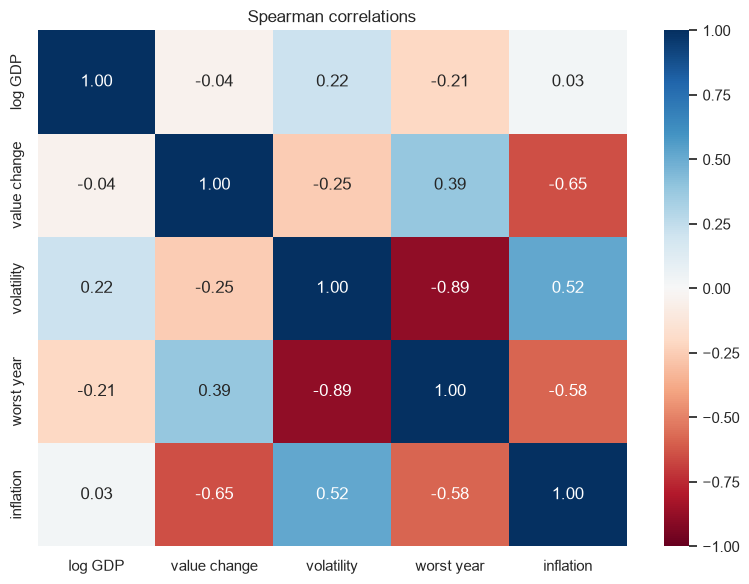

In [62]:
plt.figure(figsize=(8, 6))
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="RdBu", vmin=-1, vmax=1,
            xticklabels=["log GDP", "value change", "volatility", "worst year", "inflation"],
            yticklabels=["log GDP", "value change", "volatility", "worst year", "inflation"])
plt.title("Spearman correlations")
plt.tight_layout()
plt.savefig("figures/6_correlation_heatmap.png", dpi=150)
plt.show()

## Conclusions

In [63]:
print("countries:", len(df), " currencies:", len(by_currency))
print("weaker vs USD:", round(weaker / len(df) * 100), "%")
print("GDP vs value change:", round(spearman.loc["log10_gdp", "value_change_pct"], 2))
print("GDP vs volatility:", round(spearman.loc["log10_gdp", "volatility_pct"], 2))
print("inflation vs value change:", round(spearman.loc["avg_inflation_pct", "value_change_pct"], 2))

countries: 166  currencies: 99
weaker vs USD: 49 %
GDP vs value change: -0.04
GDP vs volatility: 0.22
inflation vs value change: -0.65


1. About half of the currencies lost value against USD. Some lost almost everything: Argentina (-99%), Lebanon (-98%), Turkey (-93%), Nigeria (-87%), Egypt (-84%).
   The other half did not change much because they are fixed to the dollar (Gulf countries) or to the euro (CFA franc, Bulgaria, Denmark). The euro itself is about the same as in 2015.
2. The size of the economy is almost not connected with the value change (Spearman about -0.04, p = 0.58).
3. Big economies even have a bit more volatile currencies (about +0.22), because many small countries fix their currency and big ones don't.
   Without fixed currencies this connection disappears (+0.09, p = 0.27).
   So our idea "bigger economy = more stable currency" was wrong.
4. Inflation is much more important: Spearman about -0.65 with value change (p < 0.001), and -0.74 if we look only at floating currencies.
5. Lower middle income countries lost the most (median -26%). Low income looks stable only because many of them use the CFA franc.
6. If we count every currency only once, the results are almost the same.

**Limitations:** only yearly data; GDP is only for one year; some countries were removed; no inflation data for 20 countries (for example Argentina); correlation is not causation.